##### ### The University of Melbourne, School of Computing and Information Systems
# COMP30027 Machine Learning, 2026 Semester 1

## Assignment 2: Image Classification


**Student ID(s):**     `1492307`


## Feature Engineering


In [2]:
import sys
!{sys.executable} -m pip install torch torchvision
import sys
!{sys.executable} -m pip install numpy pandas pillow scikit-learn matplotlib

  Using cached torch-2.12.0-cp311-cp311-macosx_14_0_arm64.whl.metadata (31 kB)
  Using cached torchvision-0.27.0-cp311-cp311-macosx_14_0_arm64.whl.metadata (5.5 kB)
  Using cached filelock-3.29.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached fsspec-2026.4.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached torch-2.12.0-cp311-cp311-macosx_14_0_arm64.whl (88.0 MB)
Using cached torchvision-0.27.0-cp311-cp311-macosx_14_0_arm64.whl (1.8 MB)
Using cached fsspec-2026.4.0-py3-none-any.whl (203 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 14.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 11.0 MB/s eta 0:00:00a 0:00:01
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached filelock-3.29.0-py3-none-any.whl (39 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 13.5 MB/s eta 0:00:0000:0100:01
Using cached m

In [3]:
from pathlib import Path
from functools import reduce

import numpy as np
import pandas as pd
from PIL import Image

try:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader
    from torchvision import models, transforms
except ModuleNotFoundError as e:
    raise ModuleNotFoundError(
        "PyTorch/torchvision is missing. Run in a notebook cell:\n"
        "import sys\n!{sys.executable} -m pip install torch torchvision\n"
        "Then restart the kernel."
    ) from e

ID_COL = "image_id"
PATH_COLS = ["image_path", "path", "filepath", "file_path", "filename", "file_name"]
CROP_FRACTIONS = [0.90, 0.80, 0.70, 0.60, 0.50]

# Find column that has the path to image data from csv
def find_image_path_col(metadata):
    for col in PATH_COLS:
        if col in metadata.columns:
            return col
    raise ValueError(f"Could not find image path column. Actual columns: {list(metadata.columns)}")


def resolve_image_path(raw_path, image_root):
    image_root = Path(image_root)
    raw_path = Path(str(raw_path))
    if raw_path.is_absolute() and raw_path.exists():
        return raw_path
    for candidate in [image_root / raw_path, Path(".") / raw_path]:
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"Could not find image file: {raw_path}")


def crop_label(crop_fraction):
    return "full" if crop_fraction is None else f"crop{int(round(crop_fraction * 100))}"

# See which processor can be used
def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def load_feature_csv(csv_path, prefix):
    df = pd.read_csv(csv_path)
    if ID_COL not in df.columns:
        raise ValueError(f"{csv_path} does not contain {ID_COL}")
    feature_cols = [c for c in df.columns if c != ID_COL and pd.api.types.is_numeric_dtype(df[c])]
    out = df[[ID_COL] + feature_cols].copy()
    return out.rename(columns={c: f"{prefix}_{c}" for c in feature_cols})

# Combine 3 csv files 
def build_given_features(metadata_csv, hog_csv, color_csv, additional_csv, output_csv):
    metadata = pd.read_csv(metadata_csv)
    hog = load_feature_csv(hog_csv, "hog")
    color = load_feature_csv(color_csv, "color")
    additional = load_feature_csv(additional_csv, "additional")

    merged = reduce(lambda l, r: pd.merge(l, r, on=ID_COL, how="inner"), [hog, color, additional])
    given = metadata[[ID_COL]].merge(merged, on=ID_COL, how="left")
    if given.isna().any().any():
        missing = given[given.isna().any(axis=1)][ID_COL].tolist()[:10]
        raise ValueError(f"Missing given features for image_ids: {missing}")

    output_csv = Path(output_csv)
    output_csv.parent.mkdir(parents=True, exist_ok=True)
    given.to_csv(output_csv, index=False)
    print(f"Saved {output_csv} | feature count = {given.shape[1] - 1}")
    return given


class ImageDataset(Dataset):
    def __init__(self, metadata_csv, image_root, transform, crop_fraction=None):
        self.metadata = pd.read_csv(metadata_csv)
        self.image_root = Path(image_root)
        self.transform = transform
        self.crop_fraction = crop_fraction
        self.path_col = find_image_path_col(self.metadata)
        if ID_COL not in self.metadata.columns:
            raise ValueError(f"{metadata_csv} does not contain {ID_COL}")

    def __len__(self):
        return len(self.metadata)

    def center_crop_fraction(self, img):
        if self.crop_fraction is None:
            return img
        w, h = img.size
        crop_w, crop_h = int(w * self.crop_fraction), int(h * self.crop_fraction)
        left, top = (w - crop_w) // 2, (h - crop_h) // 2
        return img.crop((left, top, left + crop_w, top + crop_h))

    def __getitem__(self, idx):
        row = self.metadata.iloc[idx]
        image_id = row[ID_COL]
        image_path = resolve_image_path(row[self.path_col], self.image_root)
        img = Image.open(image_path).convert("RGB")
        img = self.center_crop_fraction(img)
        return self.transform(img), image_id

# Use existing ResNet 50 architecture + weights 
def load_resnet50_avgpool_extractor(device):
    try:
        weights = models.ResNet50_Weights.IMAGENET1K_V2
        model = models.resnet50(weights=weights)
    except AttributeError:
        model = models.resnet50(pretrained=True)

    # Manual crop first, then resize directly to 224x224.
    # This avoids an extra torchvision centre crop after our crop experiment
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])
    # Return the average pooling layer before fully connected layer/classifier
    extractor = nn.Sequential(*list(model.children())[:-1])  
    extractor.eval().to(device)
    return extractor, transform

# Create 2048 feature vectors using ResNet with specific crop level
def build_resnet_features(metadata_csv, image_root, output_csv, extractor, transform, crop_fraction, batch_size=32):
    device = next(extractor.parameters()).device
    label = crop_label(crop_fraction)
    print(f"\nBuilding ResNet-50 {label} features from {metadata_csv}")

    dataset = ImageDataset(metadata_csv, image_root, transform, crop_fraction)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)

    all_ids, all_features = [], []
    with torch.no_grad():
        for i, (images, image_ids) in enumerate(loader, start=1):
            features = extractor(images.to(device)).view(images.size(0), -1).cpu().numpy()
            all_features.append(features)
            all_ids.extend(list(image_ids))
            if i % 10 == 0:
                print(f"Processed about {i * batch_size} images...")

    X = np.vstack(all_features)
    if X.shape[1] != 2048:
        raise ValueError(f"Expected 2048 ResNet features, got {X.shape[1]}")

    df = pd.DataFrame(X, columns=[f"resnet50_{label}_{i}" for i in range(X.shape[1])])
    df.insert(0, ID_COL, all_ids)

    output_csv = Path(output_csv)
    output_csv.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(output_csv, index=False)
    print(f"Saved {output_csv} | feature count = {df.shape[1] - 1}")
    return df

# Function to coordinate other functions for each task to build features
def process_task(task_name, task_dir, output_dir, batch_size=32):
    task_dir, output_dir = Path(task_dir), Path(output_dir)
    train_metadata, test_metadata = task_dir / "train_metadata.csv", task_dir / "test_metadata.csv"
    hog_csv, color_csv, additional_csv = task_dir / "hog_pca.csv", task_dir / "color_histogram.csv", task_dir / "additional_features.csv"

    print("\n" + "=" * 90)
    print(f"Processing {task_name}")
    print("=" * 90)

    build_given_features(train_metadata, hog_csv, color_csv, additional_csv, output_dir / "train_given_219.csv")
    build_given_features(test_metadata, hog_csv, color_csv, additional_csv, output_dir / "test_given_219.csv")

    device = get_device()
    print("Device:", device)
    extractor, transform = load_resnet50_avgpool_extractor(device)

    for frac in [None] + CROP_FRACTIONS:
        label = crop_label(frac)
        build_resnet_features(train_metadata, task_dir, output_dir / f"train_resnet50_{label}_2048.csv", extractor, transform, frac, batch_size)
        build_resnet_features(test_metadata, task_dir, output_dir / f"test_resnet50_{label}_2048.csv", extractor, transform, frac, batch_size)
        

TASK1_DIR = Path("task1_data")
TASK2_DIR = Path("task2_data")
OUTPUT_TASK1 = Path("processed/task1_resnet50_crop_experiment")
OUTPUT_TASK2 = Path("processed/task2_resnet50_crop_experiment")

RUN_TASK1 = True
RUN_TASK2 = True
BATCH_SIZE = 32

if RUN_TASK1:
    process_task("task1", TASK1_DIR, OUTPUT_TASK1, BATCH_SIZE)
if RUN_TASK2:
    process_task("task2", TASK2_DIR, OUTPUT_TASK2, BATCH_SIZE)


Processing task1
Saved processed/task1_resnet50_crop_experiment/train_given_219.csv | feature count = 219
Saved processed/task1_resnet50_crop_experiment/test_given_219.csv | feature count = 219
Device: mps

Building ResNet-50 full features from task1_data/train_metadata.csv
Processed about 320 images...
Processed about 640 images...
Processed about 960 images...
Processed about 1280 images...
Processed about 1600 images...
Processed about 1920 images...
Processed about 2240 images...
Processed about 2560 images...
Processed about 2880 images...
Processed about 3200 images...
Processed about 3520 images...
Saved processed/task1_resnet50_crop_experiment/train_resnet50_full_2048.csv | feature count = 2048

Building ResNet-50 full features from task1_data/test_metadata.csv
Processed about 320 images...
Processed about 640 images...
Processed about 960 images...
Processed about 1280 images...
Saved processed/task1_resnet50_crop_experiment/test_resnet50_full_2048.csv | feature count = 2048


## Random Forest

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


ID_COL = "image_id"
LABEL_COLS = ["class_id", "label", "class_name", "class", "category"]

CROP_ORDER = [
    ("full", 0),
    ("crop90", 10),
    ("crop80", 20),
    ("crop70", 30),
    ("crop60", 40),
    ("crop50", 50),
]

RESULTS_DIR = Path("results")
PREDICTION_DIR = Path("predictions")

RESULTS_DIR.mkdir(exist_ok=True)
PREDICTION_DIR.mkdir(exist_ok=True)


def find_label_col(metadata):
    for c in LABEL_COLS:
        if c in metadata.columns:
            return c

    raise ValueError(f"Could not find label column. Columns: {list(metadata.columns)}")


def load_feature_sets(task_name, feature_dir):
    """
    Load given features and all ResNet crop features for one task.
    """
    feature_dir = Path(feature_dir)

    sets = {
        "RF - Given 219": pd.read_csv(feature_dir / "train_given_219.csv")
    }

    for label, _ in CROP_ORDER:
        sets[f"RF - ResNet50 {label} 2048"] = pd.read_csv(
            feature_dir / f"train_resnet50_{label}_2048.csv"
        )

    return sets


def prepare_xy(features, metadata, label_col):
    """
    Merge metadata labels with feature DataFrame.
    """
    data = metadata[[ID_COL, label_col]].merge(
        features,
        on=ID_COL,
        how="left"
    )

    if data.isna().any().any():
        missing = data[data.isna().any(axis=1)][ID_COL].tolist()[:10]
        raise ValueError(f"Missing feature values for image_ids: {missing}")

    X = data.drop(columns=[ID_COL, label_col])
    X = X.select_dtypes(include=[np.number])

    y = data[label_col]

    return X, y


# 5 fold cross validation (80% training 20% validation split) for a list of feature sets
def evaluate_rf(metadata_csv, feature_sets, n_splits=5, random_state=42):
    metadata = pd.read_csv(metadata_csv)
    label_col = find_label_col(metadata)

    prepared = {}

    for name, df in feature_sets.items():
        X, y = prepare_xy(df, metadata, label_col)
        prepared[name] = (X, y)
        print(f"{name}: X shape = {X.shape}")

    first_name = list(prepared.keys())[0]
    y = prepared[first_name][1]

    # Shuffle the data first to randomise
    skf = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )

    rows = []

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(prepared[first_name][0], y),
        start=1
    ):
        print("=" * 80)
        print(f"Fold {fold}")

        row = {"fold": fold}

        for name, (X, y_current) in prepared.items():
            model = RandomForestClassifier(
                n_estimators=500,
                max_depth=None,
                max_features="sqrt",
                n_jobs=-1,
                class_weight="balanced",
                random_state=random_state,
            )
            # train the model using the features in the index
            model.fit(
                X.iloc[train_idx],
                y_current.iloc[train_idx]
            )

            pred = model.predict(X.iloc[val_idx])

            acc = accuracy_score(
                y_current.iloc[val_idx],
                pred
            )

            row[name] = acc

            print(f"{name}: {acc:.4f}")

        rows.append(row)

    results = pd.DataFrame(rows)

    summary = pd.DataFrame([
        {
            "feature_set": name,
            "mean_accuracy": results[name].mean(),
            "std_accuracy": results[name].std()
        }
        for name in feature_sets
    ]).sort_values(
        "mean_accuracy",
        ascending=False
    ).reset_index(drop=True)

    crop_rows = []

    for label, cropped_percent in CROP_ORDER:
        col = f"RF - ResNet50 {label} 2048"

        if col in results.columns:
            crop_rows.append({
                "crop": label,
                "crop_percent": cropped_percent,
                "mean_accuracy": results[col].mean(),
                "std_accuracy": results[col].std(),
            })

    crop_trend = pd.DataFrame(crop_rows)

    return results, summary, crop_trend


def run_task(task_name, metadata_csv, feature_dir, output_dir):
    print("\n" + "#" * 100)
    print(f"{task_name.upper()} RANDOM FOREST")
    print("#" * 100)

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    feature_sets = load_feature_sets(task_name, feature_dir)

    results, summary, crop_trend = evaluate_rf(
        metadata_csv=metadata_csv,
        feature_sets=feature_sets
    )

    results.to_csv(output_dir / f"rf_{task_name}_results.csv", index=False)
    summary.to_csv(output_dir / f"rf_{task_name}_summary.csv", index=False)
    crop_trend.to_csv(output_dir / f"rf_{task_name}_crop_trend.csv", index=False)

    print("\nSummary")
    print(summary)

    print("\nCrop trend")
    print(crop_trend)

    return results, summary, crop_trend


def load_train_X_y_for_kaggle(metadata_csv, train_feature_csv):
    """
    Load all training labels and full-image ResNet features.
    """
    metadata = pd.read_csv(metadata_csv)
    features = pd.read_csv(train_feature_csv)

    label_col = find_label_col(metadata)

    if ID_COL not in metadata.columns:
        raise ValueError(f"{metadata_csv} does not contain {ID_COL}")

    if ID_COL not in features.columns:
        raise ValueError(f"{train_feature_csv} does not contain {ID_COL}")

    data = metadata[[ID_COL, label_col]].merge(
        features,
        on=ID_COL,
        how="left"
    )

    if data.isna().any().any():
        missing = data[data.isna().any(axis=1)][ID_COL].tolist()[:10]
        raise ValueError(f"Missing feature values for image_ids: {missing}")

    X_train = data.drop(columns=[ID_COL, label_col])
    X_train = X_train.select_dtypes(include=[np.number])

    y_train = data[label_col]

    return X_train, y_train, label_col


def load_test_X_for_kaggle(test_feature_csv, train_columns):
    """
    Load test ResNet features and align columns with training features.
    """
    test_features = pd.read_csv(test_feature_csv)

    if ID_COL not in test_features.columns:
        raise ValueError(f"{test_feature_csv} does not contain {ID_COL}")

    test_image_ids = test_features[ID_COL].copy()

    X_test = test_features.drop(columns=[ID_COL])
    X_test = X_test.select_dtypes(include=[np.number])

    # Ensure same column order as training data
    missing_cols = [col for col in train_columns if col not in X_test.columns]

    if missing_cols:
        raise ValueError(f"Test features are missing columns: {missing_cols[:10]}")

    X_test = X_test[train_columns]

    return test_image_ids, X_test


def create_kaggle_output_rf_resnet_full(
    task_name,
    train_metadata_csv,
    train_feature_csv,
    test_feature_csv,
    output_csv,
    random_state=42,
):
    print("\n" + "#" * 100)
    print(f"{task_name.upper()} KAGGLE OUTPUT: RF + RESNET FULL")
    print("#" * 100)

    X_train, y_train, label_col = load_train_X_y_for_kaggle(
        metadata_csv=train_metadata_csv,
        train_feature_csv=train_feature_csv,
    )

    test_image_ids, X_test = load_test_X_for_kaggle(
        test_feature_csv=test_feature_csv,
        train_columns=X_train.columns,
    )

    print("X_train shape:", X_train.shape)
    print("y_train shape:", y_train.shape)
    print("X_test shape:", X_test.shape)

    model = RandomForestClassifier(
        n_estimators=500,
        max_depth=None,
        max_features="sqrt",
        n_jobs=-1,
        class_weight="balanced",
        random_state=random_state,
    )

    # Final model is trained on all labelled training data
    model.fit(X_train, y_train)

    test_predictions = model.predict(X_test)

    kaggle_output = pd.DataFrame({
        ID_COL: test_image_ids,
        "class_id": test_predictions,
    })

    output_csv = Path(output_csv)
    output_csv.parent.mkdir(parents=True, exist_ok=True)

    kaggle_output.to_csv(output_csv, index=False)

    print(f"Saved Kaggle output: {output_csv}")
    print(kaggle_output.head())

    return kaggle_output



rf_task1_results_df, rf_task1_summary_df, rf_task1_crop_trend_df = run_task(
    "task1",
    "task1_data/train_metadata.csv",
    "processed/task1_resnet50_crop_experiment",
    RESULTS_DIR
)

rf_task2_results_df, rf_task2_summary_df, rf_task2_crop_trend_df = run_task(
    "task2",
    "task2_data/train_metadata.csv",
    "processed/task2_resnet50_crop_experiment",
    RESULTS_DIR
)


kaggle_output_task1_df = create_kaggle_output_rf_resnet_full(
    task_name="task1",
    train_metadata_csv="task1_data/train_metadata.csv",
    train_feature_csv="processed/task1_resnet50_crop_experiment/train_resnet50_full_2048.csv",
    test_feature_csv="processed/task1_resnet50_crop_experiment/test_resnet50_full_2048.csv",
    output_csv=PREDICTION_DIR / "kaggle_output_task1.csv",
)

kaggle_output_task2_df = create_kaggle_output_rf_resnet_full(
    task_name="task2",
    train_metadata_csv="task2_data/train_metadata.csv",
    train_feature_csv="processed/task2_resnet50_crop_experiment/train_resnet50_full_2048.csv",
    test_feature_csv="processed/task2_resnet50_crop_experiment/test_resnet50_full_2048.csv",
    output_csv=PREDICTION_DIR / "kaggle_output_task2.csv",
)

print("\nFinal outputs created:")
print(RESULTS_DIR / "rf_task1_results.csv")
print(RESULTS_DIR / "rf_task1_summary.csv")
print(RESULTS_DIR / "rf_task1_crop_trend.csv")
print(RESULTS_DIR / "rf_task2_results.csv")
print(RESULTS_DIR / "rf_task2_summary.csv")
print(RESULTS_DIR / "rf_task2_crop_trend.csv")
print(PREDICTION_DIR / "kaggle_output_task1.csv")
print(PREDICTION_DIR / "kaggle_output_task2.csv")

print("\nKaggle output shapes:")
print("Task 1:", kaggle_output_task1_df.shape)
print("Task 2:", kaggle_output_task2_df.shape)


####################################################################################################
TASK1 RANDOM FOREST
####################################################################################################
RF - Given 219: X shape = (3750, 219)
RF - ResNet50 full 2048: X shape = (3750, 2048)
RF - ResNet50 crop90 2048: X shape = (3750, 2048)
RF - ResNet50 crop80 2048: X shape = (3750, 2048)
RF - ResNet50 crop70 2048: X shape = (3750, 2048)
RF - ResNet50 crop60 2048: X shape = (3750, 2048)
RF - ResNet50 crop50 2048: X shape = (3750, 2048)
Fold 1
RF - Given 219: 0.5107
RF - ResNet50 full 2048: 0.8747
RF - ResNet50 crop90 2048: 0.8653
RF - ResNet50 crop80 2048: 0.8653
RF - ResNet50 crop70 2048: 0.8280
RF - ResNet50 crop60 2048: 0.7880
RF - ResNet50 crop50 2048: 0.7373
Fold 2
RF - Given 219: 0.5667
RF - ResNet50 full 2048: 0.9040
RF - ResNet50 crop90 2048: 0.8933
RF - ResNet50 crop80 2048: 0.8733
RF - ResNet50 crop70 2048: 0.8200
RF - ResNet50 crop60 2048: 0.8013
RF - ResNet

## SVM

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


ID_COL = "image_id"
LABEL_COLS = ["class_id", "label", "class_name", "class", "category"]

CROP_ORDER = [
    ("full", 0),
    ("crop90", 10),
    ("crop80", 20),
    ("crop70", 30),
    ("crop60", 40),
    ("crop50", 50),
]

C_VALUES = [0.1, 1.0, 10.0, 100.0, 1000.0]

# C value used to create final Kaggle prediction files, this was determined with experiements
FINAL_C = 10.0

RESULTS_DIR = Path("results")
PREDICTION_DIR = Path("predictions")

RESULTS_DIR.mkdir(exist_ok=True)
PREDICTION_DIR.mkdir(exist_ok=True)


def find_label_col(metadata):
    for c in LABEL_COLS:
        if c in metadata.columns:
            return c

    raise ValueError(f"Could not find label column. Columns: {list(metadata.columns)}")


def load_feature_sets(feature_dir):
    """
    Load given features and all ResNet crop features for one task.
    """
    feature_dir = Path(feature_dir)

    sets = {
        "SVM - Given 219": pd.read_csv(feature_dir / "train_given_219.csv")
    }

    for label, _ in CROP_ORDER:
        sets[f"SVM - ResNet50 {label} 2048"] = pd.read_csv(
            feature_dir / f"train_resnet50_{label}_2048.csv"
        )

    return sets


def prepare_xy(features, metadata, label_col):
    """
    Merge training labels with feature DataFrame.
    """
    data = metadata[[ID_COL, label_col]].merge(
        features,
        on=ID_COL,
        how="left"
    )

    if data.isna().any().any():
        missing = data[data.isna().any(axis=1)][ID_COL].tolist()[:10]
        raise ValueError(f"Missing feature values for image_ids: {missing}")

    X = data.drop(columns=[ID_COL, label_col])
    X = X.select_dtypes(include=[np.number])

    y = data[label_col]

    return X, y


def make_svm(C):
    """
    RBF SVM with StandardScaler.
    Scaling is inside the pipeline, so each fold fits the scaler only on training data.
    """
    return make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=C,
            gamma="scale"
        )
    )


# 5 fold cross validataion toward a list of feature sets. This include features with different crop levels, and given feature
def evaluate_svm_once(metadata_csv, feature_sets, C, n_splits=5, random_state=42):
    metadata = pd.read_csv(metadata_csv)
    label_col = find_label_col(metadata)

    prepared = {}

    for name, df in feature_sets.items():
        X, y = prepare_xy(df, metadata, label_col)
        prepared[name] = (X, y)
        print(f"{name}: X shape = {X.shape}")

    first_name = list(prepared.keys())[0]
    y = prepared[first_name][1]

    skf = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )

    rows = []

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(prepared[first_name][0], y),
        start=1
    ):
        print("=" * 80)
        print(f"C={C}, Fold {fold}")

        row = {
            "C": C,
            "fold": fold
        }

        for name, (X, y_current) in prepared.items():
            model = make_svm(C)

            model.fit(
                X.iloc[train_idx],
                y_current.iloc[train_idx]
            )

            pred = model.predict(X.iloc[val_idx])

            acc = accuracy_score(
                y_current.iloc[val_idx],
                pred
            )

            row[name] = acc

            print(f"{name}: {acc:.4f}")

        rows.append(row)

    results = pd.DataFrame(rows)

    summary = pd.DataFrame([
        {
            "C": C,
            "feature_set": name,
            "mean_accuracy": results[name].mean(),
            "std_accuracy": results[name].std()
        }
        for name in feature_sets
    ]).sort_values(
        "mean_accuracy",
        ascending=False
    ).reset_index(drop=True)

    crop_rows = []

    for label, cropped_percent in CROP_ORDER:
        col = f"SVM - ResNet50 {label} 2048"

        if col in results.columns:
            crop_rows.append({
                "C": C,
                "crop": label,
                "crop_percent": cropped_percent,
                "mean_accuracy": results[col].mean(),
                "std_accuracy": results[col].std(),
            })

    crop_trend = pd.DataFrame(crop_rows)

    return results, summary, crop_trend


def run_task(task_name, metadata_csv, feature_dir, output_dir):
    print("\n" + "#" * 100)
    print(f"{task_name.upper()} SVM")
    print("#" * 100)

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    feature_sets = load_feature_sets(feature_dir)

    all_results = []
    all_summaries = []
    all_trends = []

    # Experiment to see how accuracy varies with different error penalty value
    for C in C_VALUES:
        results, summary, crop_trend = evaluate_svm_once(
            metadata_csv=metadata_csv,
            feature_sets=feature_sets,
            C=C
        )

        all_results.append(results)
        all_summaries.append(summary)
        all_trends.append(crop_trend)

    results_df = pd.concat(all_results, ignore_index=True)

    summary_df = pd.concat(
        all_summaries,
        ignore_index=True
    ).sort_values(
        "mean_accuracy",
        ascending=False
    ).reset_index(drop=True)

    crop_trend_df = pd.concat(all_trends, ignore_index=True)

    results_df.to_csv(output_dir / f"svm_{task_name}_results.csv", index=False)
    summary_df.to_csv(output_dir / f"svm_{task_name}_summary.csv", index=False)
    crop_trend_df.to_csv(output_dir / f"svm_{task_name}_crop_trend.csv", index=False)

    print("\nOverall best")
    print(summary_df.head(10))

    return results_df, summary_df, crop_trend_df


def load_train_X_y_for_kaggle(metadata_csv, train_feature_csv):
    """
    Load all training labels and selected ResNet features.
    """
    metadata = pd.read_csv(metadata_csv)
    features = pd.read_csv(train_feature_csv)

    label_col = find_label_col(metadata)

    if ID_COL not in metadata.columns:
        raise ValueError(f"{metadata_csv} does not contain {ID_COL}")

    if ID_COL not in features.columns:
        raise ValueError(f"{train_feature_csv} does not contain {ID_COL}")

    data = metadata[[ID_COL, label_col]].merge(
        features,
        on=ID_COL,
        how="left"
    )

    if data.isna().any().any():
        missing = data[data.isna().any(axis=1)][ID_COL].tolist()[:10]
        raise ValueError(f"Missing feature values for image_ids: {missing}")

    X_train = data.drop(columns=[ID_COL, label_col])
    X_train = X_train.select_dtypes(include=[np.number])

    y_train = data[label_col]

    return X_train, y_train, label_col


def load_test_X_for_kaggle(test_feature_csv, train_columns):
    """
    Load test features and align columns with training features.
    """
    test_features = pd.read_csv(test_feature_csv)

    if ID_COL not in test_features.columns:
        raise ValueError(f"{test_feature_csv} does not contain {ID_COL}")

    test_image_ids = test_features[ID_COL].copy()

    X_test = test_features.drop(columns=[ID_COL])
    X_test = X_test.select_dtypes(include=[np.number])

    missing_cols = [col for col in train_columns if col not in X_test.columns]

    if missing_cols:
        raise ValueError(f"Test features are missing columns: {missing_cols[:10]}")

    X_test = X_test[train_columns]

    return test_image_ids, X_test


def create_kaggle_output_svm_resnet(
    task_name,
    train_metadata_csv,
    train_feature_csv,
    test_feature_csv,
    output_csv,
    C=FINAL_C,
):
    print("\n" + "#" * 100)
    print(f"{task_name.upper()} KAGGLE OUTPUT: SVM + RESNET")
    print("#" * 100)

    X_train, y_train, label_col = load_train_X_y_for_kaggle(
        metadata_csv=train_metadata_csv,
        train_feature_csv=train_feature_csv,
    )

    test_image_ids, X_test = load_test_X_for_kaggle(
        test_feature_csv=test_feature_csv,
        train_columns=X_train.columns,
    )

    print("Selected C:", C)
    print("X_train shape:", X_train.shape)
    print("y_train shape:", y_train.shape)
    print("X_test shape:", X_test.shape)

    model = make_svm(C)

    # Final model is trained on all labelled training data.
    model.fit(X_train, y_train)

    test_predictions = model.predict(X_test)

    kaggle_output = pd.DataFrame({
        ID_COL: test_image_ids,
        "class_id": test_predictions,
    })

    output_csv = Path(output_csv)
    output_csv.parent.mkdir(parents=True, exist_ok=True)

    kaggle_output.to_csv(output_csv, index=False)

    print(f"Saved Kaggle output: {output_csv}")
    print(kaggle_output.head())

    return kaggle_output


svm_task1_results_df, svm_task1_summary_df, svm_task1_crop_trend_df = run_task(
    "task1",
    "task1_data/train_metadata.csv",
    "processed/task1_resnet50_crop_experiment",
    RESULTS_DIR
)

svm_task2_results_df, svm_task2_summary_df, svm_task2_crop_trend_df = run_task(
    "task2",
    "task2_data/train_metadata.csv",
    "processed/task2_resnet50_crop_experiment",
    RESULTS_DIR
)


# For assignment submission, using full image ResNet feature for task 1 and 30% crop ResNet feature for task 2 since they produced the highest accuracy
svm_kaggle_output_task1_df = create_kaggle_output_svm_resnet(
    task_name="task1",
    train_metadata_csv="task1_data/train_metadata.csv",
    train_feature_csv="processed/task1_resnet50_crop_experiment/train_resnet50_full_2048.csv",
    test_feature_csv="processed/task1_resnet50_crop_experiment/test_resnet50_full_2048.csv",
    output_csv=PREDICTION_DIR / "svm_resnet_task1.csv",
    C=FINAL_C,
)

svm_kaggle_output_task2_df = create_kaggle_output_svm_resnet(
    task_name="task2",
    train_metadata_csv="task2_data/train_metadata.csv",
    train_feature_csv="processed/task2_resnet50_crop_experiment/train_resnet50_crop70_2048.csv",
    test_feature_csv="processed/task2_resnet50_crop_experiment/test_resnet50_crop70_2048.csv",
    output_csv=PREDICTION_DIR / "svm_resnet_task2.csv",
    C=FINAL_C,
)

print("\nFinal outputs created:")
print(RESULTS_DIR / "svm_task1_results.csv")
print(RESULTS_DIR / "svm_task1_summary.csv")
print(RESULTS_DIR / "svm_task1_crop_trend.csv")
print(RESULTS_DIR / "svm_task2_results.csv")
print(RESULTS_DIR / "svm_task2_summary.csv")
print(RESULTS_DIR / "svm_task2_crop_trend.csv")
print(PREDICTION_DIR / "svm_resnet_task1.csv")
print(PREDICTION_DIR / "svm_resnet_task2.csv")

print("\nKaggle output shapes:")
print("Task 1:", svm_kaggle_output_task1_df.shape)
print("Task 2:", svm_kaggle_output_task2_df.shape)


####################################################################################################
TASK1 SVM
####################################################################################################
SVM - Given 219: X shape = (3750, 219)
SVM - ResNet50 full 2048: X shape = (3750, 2048)
SVM - ResNet50 crop90 2048: X shape = (3750, 2048)
SVM - ResNet50 crop80 2048: X shape = (3750, 2048)
SVM - ResNet50 crop70 2048: X shape = (3750, 2048)
SVM - ResNet50 crop60 2048: X shape = (3750, 2048)
SVM - ResNet50 crop50 2048: X shape = (3750, 2048)
C=0.1, Fold 1
SVM - Given 219: 0.3547
SVM - ResNet50 full 2048: 0.6933
SVM - ResNet50 crop90 2048: 0.6907
SVM - ResNet50 crop80 2048: 0.6827
SVM - ResNet50 crop70 2048: 0.6560
SVM - ResNet50 crop60 2048: 0.6160
SVM - ResNet50 crop50 2048: 0.5840
C=0.1, Fold 2
SVM - Given 219: 0.3613
SVM - ResNet50 full 2048: 0.7160
SVM - ResNet50 crop90 2048: 0.7347
SVM - ResNet50 crop80 2048: 0.6987
SVM - ResNet50 crop70 2048: 0.6787
SVM - ResNet50 crop60 

## CNN

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

try:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader, Subset
except ModuleNotFoundError as e:
    raise ModuleNotFoundError(
        "PyTorch is missing. Run in a notebook cell:\n"
        "import sys\n!{sys.executable} -m pip install torch\n"
        "Then restart the kernel."
    ) from e

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score


ID_COL = "image_id"

PATH_COLS = [
    "image_path",
    "path",
    "filepath",
    "file_path",
    "filename",
    "file_name",
]

LABEL_COLS = [
    "class_id",
    "label",
    "class_name",
    "class",
    "category",
]

CROP_FRACTIONS = [1.0, 0.90, 0.80, 0.70, 0.60, 0.50]

RESULTS_DIR = Path("results")
PREDICTION_DIR = Path("predictions")

RESULTS_DIR.mkdir(exist_ok=True)
PREDICTION_DIR.mkdir(exist_ok=True)


def find_col(df, options, kind):
    for c in options:
        if c in df.columns:
            return c

    raise ValueError(f"Could not find {kind} column. Columns: {list(df.columns)}")


def resolve_image_path(raw_path, image_root):
    raw_path = Path(str(raw_path))
    image_root = Path(image_root)

    if raw_path.is_absolute() and raw_path.exists():
        return raw_path

    for candidate in [image_root / raw_path, Path(".") / raw_path]:
        if candidate.exists():
            return candidate

    raise FileNotFoundError(f"Could not find image file: {raw_path}")


def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")

    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return torch.device("mps")

    return torch.device("cpu")


def crop_name(frac):
    return "full100" if frac == 1.0 else f"crop{int(round(frac * 100))}"


class CroppedImageDataset(Dataset):
    def __init__(self, metadata_csv, image_root, crop_fraction=1.0):
        self.metadata = pd.read_csv(metadata_csv)
        self.image_root = Path(image_root)
        self.crop_fraction = crop_fraction

        self.path_col = find_col(self.metadata, PATH_COLS, "image path")
        self.label_col = find_col(self.metadata, LABEL_COLS, "label")

        self.output_size = self.infer_image_size()
        self.labels = self.metadata[self.label_col].values

    def infer_image_size(self):
        path = resolve_image_path(
            self.metadata.iloc[0][self.path_col],
            self.image_root
        )

        img = Image.open(path).convert("RGB")
        w, h = img.size

        return (h, w)

    def __len__(self):
        return len(self.metadata)

    def center_crop(self, img):
        if self.crop_fraction == 1.0:
            return img

        w, h = img.size

        crop_w = int(w * self.crop_fraction)
        crop_h = int(h * self.crop_fraction)

        left = (w - crop_w) // 2
        top = (h - crop_h) // 2

        return img.crop((left, top, left + crop_w, top + crop_h))

    def to_tensor(self, img):
        target_h, target_w = self.output_size

        img = self.center_crop(img)
        img = img.resize((target_w, target_h), Image.BILINEAR)

        arr = np.asarray(img, dtype=np.float32) / 255.0

        # H x W x C -> C x H x W
        arr = np.transpose(arr, (2, 0, 1))

        return torch.tensor(arr, dtype=torch.float32)

    def __getitem__(self, idx):
        row = self.metadata.iloc[idx]

        img = Image.open(
            resolve_image_path(row[self.path_col], self.image_root)
        ).convert("RGB")

        x = self.to_tensor(img)
        y = int(row[self.label_col])

        return x, y


class CroppedImageTestDataset(Dataset):
    def __init__(self, metadata_csv, image_root, crop_fraction=1.0, output_size=None):
        self.metadata = pd.read_csv(metadata_csv)
        self.image_root = Path(image_root)
        self.crop_fraction = crop_fraction

        self.path_col = find_col(self.metadata, PATH_COLS, "image path")

        if ID_COL not in self.metadata.columns:
            raise ValueError(f"{metadata_csv} does not contain {ID_COL}")

        if output_size is None:
            self.output_size = self.infer_image_size()
        else:
            self.output_size = output_size

    def infer_image_size(self):
        path = resolve_image_path(
            self.metadata.iloc[0][self.path_col],
            self.image_root
        )

        img = Image.open(path).convert("RGB")
        w, h = img.size

        return (h, w)

    def __len__(self):
        return len(self.metadata)

    def center_crop(self, img):
        if self.crop_fraction == 1.0:
            return img

        w, h = img.size

        crop_w = int(w * self.crop_fraction)
        crop_h = int(h * self.crop_fraction)

        left = (w - crop_w) // 2
        top = (h - crop_h) // 2

        return img.crop((left, top, left + crop_w, top + crop_h))

    def to_tensor(self, img):
        target_h, target_w = self.output_size

        img = self.center_crop(img)
        img = img.resize((target_w, target_h), Image.BILINEAR)

        arr = np.asarray(img, dtype=np.float32) / 255.0
        arr = np.transpose(arr, (2, 0, 1))

        return torch.tensor(arr, dtype=torch.float32)

    def __getitem__(self, idx):
        row = self.metadata.iloc[idx]

        image_id = row[ID_COL]

        img = Image.open(
            resolve_image_path(row[self.path_col], self.image_root)
        ).convert("RGB")

        x = self.to_tensor(img)

        return x, image_id


class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        # 4 convolution blocks
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(256),

            nn.AdaptiveAvgPool2d((1, 1)),
        )
        # 256 feature vectors used by fully connected layer to produce output
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        loss = criterion(model(x), y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)

    return total_loss / len(loader.dataset)


def evaluate(model, loader, device):
    model.eval()

    preds = []
    labels = []

    with torch.no_grad():
        for x, y in loader:
            pred = torch.argmax(
                model(x.to(device)),
                dim=1
            ).cpu().numpy()

            preds.extend(pred)
            labels.extend(y.numpy())

    return accuracy_score(labels, preds)



def run_crop_cv(
    task_name,
    metadata_csv,
    image_root,
    crop_fraction,
    epochs=15,
    batch_size=64,
    lr=1e-3,
    weight_decay=1e-4,
    n_splits=5,
    random_state=42,
):
    device = get_device()

    dataset = CroppedImageDataset(
        metadata_csv=metadata_csv,
        image_root=image_root,
        crop_fraction=crop_fraction,
    )

    labels = dataset.labels
    num_classes = len(np.unique(labels))

    skf = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )

    print("\n" + "=" * 90)
    print(f"{task_name} CNN | crop = {crop_name(crop_fraction)} | device = {device}")
    print("=" * 90)

    rows = []

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(np.zeros(len(labels)), labels),
        start=1
    ):
        torch.manual_seed(random_state + fold)

        train_loader = DataLoader(
            Subset(dataset, train_idx),
            batch_size=batch_size,
            shuffle=True,
            num_workers=0,
        )

        val_loader = DataLoader(
            Subset(dataset, val_idx),
            batch_size=batch_size,
            shuffle=False,
            num_workers=0,
        )

        model = SimpleCNN(num_classes).to(device)

        criterion = nn.CrossEntropyLoss()

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay,
        )

        best_acc = 0.0

        for epoch in range(1, epochs + 1):
            train_loss = train_one_epoch(
                model=model,
                loader=train_loader,
                criterion=criterion,
                optimizer=optimizer,
                device=device,
            )

            val_acc = evaluate(
                model=model,
                loader=val_loader,
                device=device,
            )

            best_acc = max(best_acc, val_acc)

            print(
                f"Fold {fold} | Epoch {epoch:02d}/{epochs} "
                f"| loss={train_loss:.4f} "
                f"| val_acc={val_acc:.4f} "
                f"| best={best_acc:.4f}"
            )

        rows.append({
            "fold": fold,
            "crop": crop_name(crop_fraction),
            "crop_percent": int(round((1 - crop_fraction) * 100)),
            "best_val_accuracy": best_acc,
        })

    return pd.DataFrame(rows)


def run_task(task_name, metadata_csv, image_root, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    results = pd.concat(
        [
            run_crop_cv(
                task_name=task_name,
                metadata_csv=metadata_csv,
                image_root=image_root,
                crop_fraction=f,
            )
            for f in CROP_FRACTIONS
        ],
        ignore_index=True
    )

    summary = (
        results
        .groupby(["crop", "crop_percent"], as_index=False)
        .agg(
            mean_accuracy=("best_val_accuracy", "mean"),
            std_accuracy=("best_val_accuracy", "std"),
        )
        .sort_values("crop_percent")
        .reset_index(drop=True)
    )

    summary_by_accuracy = (
        summary
        .sort_values("mean_accuracy", ascending=False)
        .reset_index(drop=True)
    )

    results.to_csv(output_dir / f"cnn_{task_name}_results.csv", index=False)
    summary.to_csv(output_dir / f"cnn_{task_name}_crop_summary.csv", index=False)
    summary_by_accuracy.to_csv(
        output_dir / f"cnn_{task_name}_summary_by_accuracy.csv",
        index=False
    )

    print("\nSummary by accuracy")
    print(summary_by_accuracy)

    return results, summary, summary_by_accuracy


# For assignment submission, 10% cropped image for task 1 and 50% cropped image for task 2 are used
# Those images produced highest accuracy during the cross validation
def train_final_cnn_and_create_kaggle_output(
    task_name,
    train_metadata_csv,
    test_metadata_csv,
    image_root,
    crop_fraction,
    output_csv,
    epochs=15,
    batch_size=64,
    lr=1e-3,
    weight_decay=1e-4,
    random_state=42,
):
    print("\n" + "#" * 100)
    print(f"{task_name.upper()} KAGGLE OUTPUT: CNN | crop = {crop_name(crop_fraction)}")
    print("#" * 100)

    torch.manual_seed(random_state)

    device = get_device()

    train_dataset = CroppedImageDataset(
        metadata_csv=train_metadata_csv,
        image_root=image_root,
        crop_fraction=crop_fraction,
    )

    labels = train_dataset.labels
    unique_labels = sorted(np.unique(labels))
    num_classes = len(unique_labels)

    expected_labels = list(range(num_classes))

    if list(unique_labels) != expected_labels:
        raise ValueError(
            "This CNN program assumes class labels are 0, 1, ..., num_classes-1.\n"
            f"Found labels: {unique_labels}"
        )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
    )

    model = SimpleCNN(num_classes).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    print("Device:", device)
    print("Training samples:", len(train_dataset))
    print("Number of classes:", num_classes)
    print("Output image size:", train_dataset.output_size)

    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=device,
        )

        print(
            f"Final training | Epoch {epoch:02d}/{epochs} "
            f"| loss={train_loss:.4f}"
        )

    test_dataset = CroppedImageTestDataset(
        metadata_csv=test_metadata_csv,
        image_root=image_root,
        crop_fraction=crop_fraction,
        output_size=train_dataset.output_size,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
    )

    model.eval()

    all_image_ids = []
    all_predictions = []

    with torch.no_grad():
        for x, image_ids in test_loader:
            x = x.to(device)

            logits = model(x)
            preds = torch.argmax(logits, dim=1).cpu().numpy()

            all_image_ids.extend(list(image_ids))
            all_predictions.extend(preds.tolist())

    kaggle_output = pd.DataFrame({
        ID_COL: all_image_ids,
        "class_id": all_predictions,
    })

    output_csv = Path(output_csv)
    output_csv.parent.mkdir(parents=True, exist_ok=True)

    kaggle_output.to_csv(output_csv, index=False)

    print(f"Saved Kaggle output: {output_csv}")
    print(kaggle_output.head())

    return kaggle_output


cnn_task1_results_df, cnn_task1_crop_summary_df, cnn_task1_summary_by_accuracy_df = run_task(
    "task1",
    "task1_data/train_metadata.csv",
    "task1_data",
    RESULTS_DIR,
)

cnn_task2_results_df, cnn_task2_crop_summary_df, cnn_task2_summary_by_accuracy_df = run_task(
    "task2",
    "task2_data/train_metadata.csv",
    "task2_data",
    RESULTS_DIR,
)

cnn_kaggle_output_task1_df = train_final_cnn_and_create_kaggle_output(
    task_name="task1",
    train_metadata_csv="task1_data/train_metadata.csv",
    test_metadata_csv="task1_data/test_metadata.csv",
    image_root="task1_data",
    crop_fraction=0.90,
    output_csv=PREDICTION_DIR / "cnn_task1.csv",
)

cnn_kaggle_output_task2_df = train_final_cnn_and_create_kaggle_output(
    task_name="task2",
    train_metadata_csv="task2_data/train_metadata.csv",
    test_metadata_csv="task2_data/test_metadata.csv",
    image_root="task2_data",
    crop_fraction=0.50,
    output_csv=PREDICTION_DIR / "cnn_task2.csv",
)


print("\nFinal outputs created:")
print(RESULTS_DIR / "cnn_task1_results.csv")
print(RESULTS_DIR / "cnn_task1_crop_summary.csv")
print(RESULTS_DIR / "cnn_task1_summary_by_accuracy.csv")
print(RESULTS_DIR / "cnn_task2_results.csv")
print(RESULTS_DIR / "cnn_task2_crop_summary.csv")
print(RESULTS_DIR / "cnn_task2_summary_by_accuracy.csv")
print(PREDICTION_DIR / "cnn_task1.csv")
print(PREDICTION_DIR / "cnn_task2.csv")

print("\nKaggle output shapes:")
print("Task 1:", cnn_kaggle_output_task1_df.shape)
print("Task 2:", cnn_kaggle_output_task2_df.shape)


task1 CNN | crop = full100 | device = mps
Fold 1 | Epoch 01/15 | loss=1.6347 | val_acc=0.2453 | best=0.2453
Fold 1 | Epoch 02/15 | loss=1.2978 | val_acc=0.4520 | best=0.4520
Fold 1 | Epoch 03/15 | loss=1.1405 | val_acc=0.5093 | best=0.5093
Fold 1 | Epoch 04/15 | loss=1.0522 | val_acc=0.5453 | best=0.5453
Fold 1 | Epoch 05/15 | loss=1.0026 | val_acc=0.5800 | best=0.5800
Fold 1 | Epoch 06/15 | loss=0.9359 | val_acc=0.5453 | best=0.5800
Fold 1 | Epoch 07/15 | loss=0.8859 | val_acc=0.5693 | best=0.5800
Fold 1 | Epoch 08/15 | loss=0.8288 | val_acc=0.5960 | best=0.5960
Fold 1 | Epoch 09/15 | loss=0.7716 | val_acc=0.5240 | best=0.5960
Fold 1 | Epoch 10/15 | loss=0.7387 | val_acc=0.5560 | best=0.5960
Fold 1 | Epoch 11/15 | loss=0.6907 | val_acc=0.5067 | best=0.5960
Fold 1 | Epoch 12/15 | loss=0.6187 | val_acc=0.5800 | best=0.5960
Fold 1 | Epoch 13/15 | loss=0.5257 | val_acc=0.6120 | best=0.6120
Fold 1 | Epoch 14/15 | loss=0.4745 | val_acc=0.6053 | best=0.6120
Fold 1 | Epoch 15/15 | loss=0.446

## Diagrams

In [7]:
import sys
!{sys.executable} -m pip install matplotlib


[notice] A new release of pip is available: 24.0 -> 26.1.1
[notice] To update, run: pip install --upgrade pip


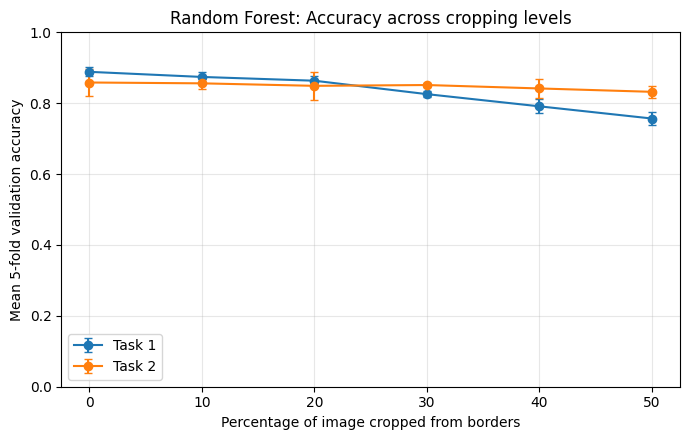

Saved figures/figure1_rf_crop_trend.png


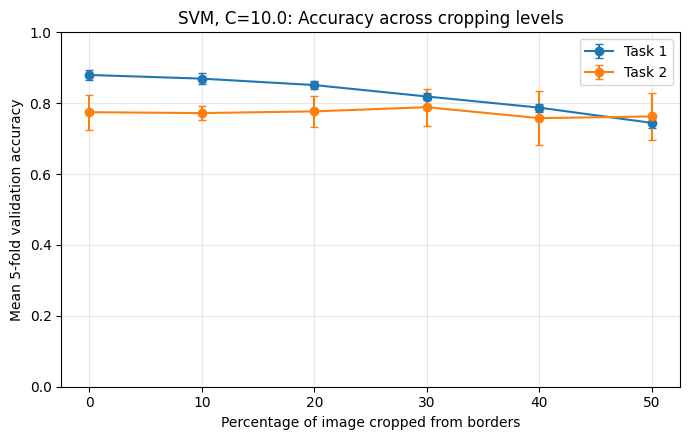

Saved figures/figure2_svm_crop_trend.png


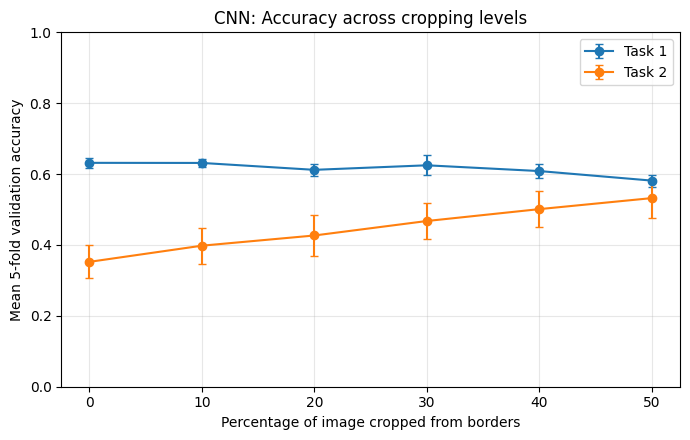

Saved figures/figure3_cnn_crop_trend.png

Feature representation table
   Task          Model  Given Feature Accuracy  ResNet Feature Accuracy
0     1  Random Forest                  0.5224                   0.8885
1     1            SVM                  0.5176                   0.8797
2     2  Random Forest                  0.3141                   0.8584
3     2            SVM                  0.2468                   0.7746


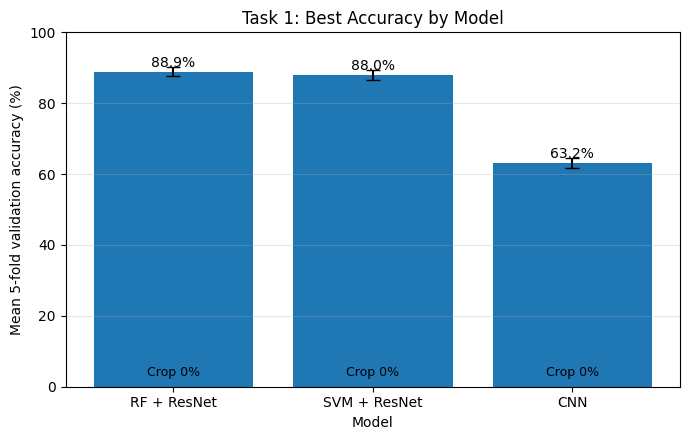

Saved figures/figure4_task1_best_model.png


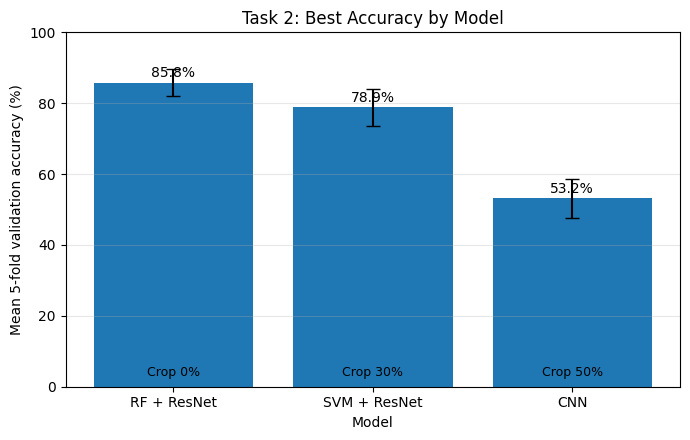

Saved figures/figure5_task2_best_model.png

Best model comparison table
   Task         Model  mean_accuracy  std_accuracy   setting
0     1   RF + ResNet         0.8885        0.0129   Crop 0%
1     1  SVM + ResNet         0.8797        0.0145   Crop 0%
2     1           CNN         0.6317        0.0148   Crop 0%
3     2   RF + ResNet         0.8584        0.0378   Crop 0%
4     2  SVM + ResNet         0.7888        0.0523  Crop 30%
5     2           CNN         0.5322        0.0547  Crop 50%

All diagrams and comparison tables created.
Figures saved in: figures
Tables saved in: tables


In [15]:
from pathlib import Path
import re

import pandas as pd
import matplotlib.pyplot as plt


RESULTS_DIR = Path("results")
FIGURE_DIR = Path("figures")
TABLE_DIR = Path("tables")

FIGURE_DIR.mkdir(exist_ok=True)
TABLE_DIR.mkdir(exist_ok=True)

SVM_C = 10.0


def read_result_csv(filename):
    path = RESULTS_DIR / filename

    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Run previous model programs first.")

    return pd.read_csv(path)


def filter_svm_c(df):
    if "C" in df.columns:
        out = df[df["C"] == SVM_C].copy()

        if out.empty:
            raise ValueError(f"No rows found for SVM C={SVM_C}")

        return out

    return df.copy()


def find_feature_row(df, keywords):
    """
    Find a row where feature_set contains all keywords.
    Example:
    keywords = ["given"]
    keywords = ["resnet50", "full"]
    """
    if "feature_set" not in df.columns:
        raise ValueError("DataFrame must contain feature_set column.")

    mask = pd.Series(True, index=df.index)
    feature_names = df["feature_set"].astype(str).str.lower()

    for keyword in keywords:
        mask &= feature_names.str.contains(keyword.lower(), regex=False)

    matched = df[mask].copy()

    if matched.empty:
        raise ValueError(
            f"No feature_set found for keywords {keywords}.\n"
            f"Available feature_set values:\n{df['feature_set'].tolist()}"
        )

    return matched.sort_values("mean_accuracy", ascending=False).iloc[0]


def find_best_resnet_row(df):
    """
    Find the best ResNet row, excluding given-feature baseline.
    """
    if "feature_set" not in df.columns:
        raise ValueError("DataFrame must contain feature_set column.")

    feature_names = df["feature_set"].astype(str).str.lower()

    matched = df[
        feature_names.str.contains("resnet50", regex=False)
        | feature_names.str.contains("resnet", regex=False)
    ].copy()

    if matched.empty:
        raise ValueError("No ResNet feature rows found.")

    return matched.sort_values("mean_accuracy", ascending=False).iloc[0]


def find_best_row(df):
    return df.sort_values("mean_accuracy", ascending=False).iloc[0]


def crop_setting_from_feature_set(feature_set):
    feature_set = str(feature_set).lower()

    if "full" in feature_set:
        return "Crop 0%"

    match = re.search(r"crop(\d+)", feature_set)

    if match:
        retained = int(match.group(1))
        cropped = 100 - retained
        return f"Crop {cropped}%"

    if "given" in feature_set:
        return "Given"

    return ""


def crop_setting_from_cnn_row(row):
    if "crop" in row:
        crop_name = str(row["crop"]).lower()

        if crop_name in ["full", "full100"]:
            return "Crop 0%"

        match = re.search(r"crop(\d+)", crop_name)

        if match:
            retained = int(match.group(1))
            cropped = 100 - retained
            return f"Crop {cropped}%"

    return f"Crop {int(row['crop_percent'])}%"


rf_task1_crop = read_result_csv("rf_task1_crop_trend.csv")
rf_task2_crop = read_result_csv("rf_task2_crop_trend.csv")

svm_task1_crop = filter_svm_c(read_result_csv("svm_task1_crop_trend.csv"))
svm_task2_crop = filter_svm_c(read_result_csv("svm_task2_crop_trend.csv"))

cnn_task1_crop = read_result_csv("cnn_task1_crop_summary.csv")
cnn_task2_crop = read_result_csv("cnn_task2_crop_summary.csv")

rf_task1_summary = read_result_csv("rf_task1_summary.csv")
rf_task2_summary = read_result_csv("rf_task2_summary.csv")

svm_task1_summary = filter_svm_c(read_result_csv("svm_task1_summary.csv"))
svm_task2_summary = filter_svm_c(read_result_csv("svm_task2_summary.csv"))

# Line chart showing how each model changes accuracy depending on crop level for task 1 and task 2
def plot_crop_trend(model_name, task1_df, task2_df, filename):
    plt.figure(figsize=(7, 4.5))

    for df, label in [(task1_df, "Task 1"), (task2_df, "Task 2")]:
        plt.errorbar(
            df["crop_percent"],
            df["mean_accuracy"],
            yerr=df["std_accuracy"],
            marker="o",
            capsize=3,
            label=label,
        )

    plt.title(f"{model_name}: Accuracy across cropping levels")
    plt.xlabel("Percentage of image cropped from borders")
    plt.ylabel("Mean 5-fold validation accuracy")
    plt.xticks([0, 10, 20, 30, 40, 50])
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    path = FIGURE_DIR / filename
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Saved {path}")


plot_crop_trend(
    model_name="Random Forest",
    task1_df=rf_task1_crop,
    task2_df=rf_task2_crop,
    filename="figure1_rf_crop_trend.png",
)

plot_crop_trend(
    model_name=f"SVM, C={SVM_C}",
    task1_df=svm_task1_crop,
    task2_df=svm_task2_crop,
    filename="figure2_svm_crop_trend.png",
)

plot_crop_trend(
    model_name="CNN",
    task1_df=cnn_task1_crop,
    task2_df=cnn_task2_crop,
    filename="figure3_cnn_crop_trend.png",
)



rf_task1_given = find_feature_row(rf_task1_summary, ["given"])
rf_task1_resnet_full = find_feature_row(rf_task1_summary, ["resnet50", "full"])

rf_task2_given = find_feature_row(rf_task2_summary, ["given"])
rf_task2_resnet_full = find_feature_row(rf_task2_summary, ["resnet50", "full"])

svm_task1_given = find_feature_row(svm_task1_summary, ["given"])
svm_task1_resnet_full = find_feature_row(svm_task1_summary, ["resnet50", "full"])

svm_task2_given = find_feature_row(svm_task2_summary, ["given"])
svm_task2_resnet_full = find_feature_row(svm_task2_summary, ["resnet50", "full"])

# Table comparing accuracy of classical models with ResNet engineered feature vs given features
feature_table = pd.DataFrame([
    {
        "Task": 1,
        "Model": "Random Forest",
        "Given Feature Accuracy": rf_task1_given["mean_accuracy"],
        "ResNet Feature Accuracy": rf_task1_resnet_full["mean_accuracy"],
    },
    {
        "Task": 1,
        "Model": "SVM",
        "Given Feature Accuracy": svm_task1_given["mean_accuracy"],
        "ResNet Feature Accuracy": svm_task1_resnet_full["mean_accuracy"],
    },
    {
        "Task": 2,
        "Model": "Random Forest",
        "Given Feature Accuracy": rf_task2_given["mean_accuracy"],
        "ResNet Feature Accuracy": rf_task2_resnet_full["mean_accuracy"],
    },
    {
        "Task": 2,
        "Model": "SVM",
        "Given Feature Accuracy": svm_task2_given["mean_accuracy"],
        "ResNet Feature Accuracy": svm_task2_resnet_full["mean_accuracy"],
    },
])

feature_table = feature_table.round(4)
feature_table.to_csv(TABLE_DIR / "table_feature_representation.csv", index=False)

print("\nFeature representation table")
print(feature_table)



def plot_best_model_bar(task_name, rows, filename):
    models = [row["Model"] for row in rows]
    accuracies = [row["mean_accuracy"] for row in rows]
    stds = [row["std_accuracy"] for row in rows]
    settings = [row["setting"] for row in rows]

    acc_percent = [a * 100 for a in accuracies]
    std_percent = [s * 100 for s in stds]

    plt.figure(figsize=(7, 4.5))

    bars = plt.bar(
        models,
        acc_percent,
        yerr=std_percent,
        capsize=5,
    )

    plt.title(f"{task_name}: Best Accuracy by Model")
    plt.xlabel("Model")
    plt.ylabel("Mean 5-fold validation accuracy (%)")
    plt.ylim(0, 100)
    plt.grid(axis="y", alpha=0.3)

    for bar, acc, setting in zip(bars, acc_percent, settings):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1.5,
            f"{acc:.1f}%",
            ha="center",
        )

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            3,
            setting,
            ha="center",
            fontsize=9,
        )

    plt.tight_layout()

    path = FIGURE_DIR / filename
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Saved {path}")


rf_task1_best = find_best_resnet_row(rf_task1_summary)
rf_task2_best = find_best_resnet_row(rf_task2_summary)

svm_task1_best = find_best_resnet_row(svm_task1_summary)
svm_task2_best = find_best_resnet_row(svm_task2_summary)

cnn_task1_best = find_best_row(cnn_task1_crop)
cnn_task2_best = find_best_row(cnn_task2_crop)

task1_best_rows = [
    {
        "Model": "RF + ResNet",
        "mean_accuracy": rf_task1_best["mean_accuracy"],
        "std_accuracy": rf_task1_best["std_accuracy"],
        "setting": crop_setting_from_feature_set(rf_task1_best["feature_set"]),
    },
    {
        "Model": "SVM + ResNet",
        "mean_accuracy": svm_task1_best["mean_accuracy"],
        "std_accuracy": svm_task1_best["std_accuracy"],
        "setting": crop_setting_from_feature_set(svm_task1_best["feature_set"]),
    },
    {
        "Model": "CNN",
        "mean_accuracy": cnn_task1_best["mean_accuracy"],
        "std_accuracy": cnn_task1_best["std_accuracy"],
        "setting": crop_setting_from_cnn_row(cnn_task1_best),
    },
]

task2_best_rows = [
    {
        "Model": "RF + ResNet",
        "mean_accuracy": rf_task2_best["mean_accuracy"],
        "std_accuracy": rf_task2_best["std_accuracy"],
        "setting": crop_setting_from_feature_set(rf_task2_best["feature_set"]),
    },
    {
        "Model": "SVM + ResNet",
        "mean_accuracy": svm_task2_best["mean_accuracy"],
        "std_accuracy": svm_task2_best["std_accuracy"],
        "setting": crop_setting_from_feature_set(svm_task2_best["feature_set"]),
    },
    {
        "Model": "CNN",
        "mean_accuracy": cnn_task2_best["mean_accuracy"],
        "std_accuracy": cnn_task2_best["std_accuracy"],
        "setting": crop_setting_from_cnn_row(cnn_task2_best),
    },
]

plot_best_model_bar(
    task_name="Task 1",
    rows=task1_best_rows,
    filename="figure4_task1_best_model.png",
)

plot_best_model_bar(
    task_name="Task 2",
    rows=task2_best_rows,
    filename="figure5_task2_best_model.png",
)

best_model_table = pd.DataFrame(
    [{"Task": 1, **row} for row in task1_best_rows]
    + [{"Task": 2, **row} for row in task2_best_rows]
)

best_model_table = best_model_table.round(4)
best_model_table.to_csv(TABLE_DIR / "table_best_model_comparison.csv", index=False)

print("\nBest model comparison table")
print(best_model_table)

print("\nAll diagrams and comparison tables created.")
print("Figures saved in:", FIGURE_DIR)
print("Tables saved in:", TABLE_DIR)

## Error Analysis

In [14]:
from pathlib import Path
import copy

import numpy as np
import pandas as pd
from PIL import Image

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

try:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader, Subset
except ModuleNotFoundError as e:
    raise ModuleNotFoundError(
        "PyTorch is missing. Run in a notebook cell:\n"
        "import sys\n!{sys.executable} -m pip install torch\n"
        "Then restart the kernel."
    ) from e

ID_COL = "image_id"

LABEL_COLS = [
    "class_id",
    "label",
    "class_name",
    "class",
    "category",
]

PATH_COLS = [
    "image_path",
    "path",
    "filepath",
    "file_path",
    "filename",
    "file_name",
]

TABLE_DIR = Path("tables")
TABLE_DIR.mkdir(exist_ok=True)

SVM_C = 10.0
N_SPLITS = 5
RANDOM_STATE = 42

CNN_EPOCHS = 15
CNN_BATCH_SIZE = 64
CNN_LR = 1e-3
CNN_WEIGHT_DECAY = 1e-4

# Run the best version of each model, and see which class has the lowest recall and confused with which another class

def find_col(df, options, kind):
    for col in options:
        if col in df.columns:
            return col

    raise ValueError(f"Could not find {kind} column. Columns: {list(df.columns)}")


def resolve_image_path(raw_path, image_root):
    raw_path = Path(str(raw_path))
    image_root = Path(image_root)

    if raw_path.is_absolute() and raw_path.exists():
        return raw_path

    for candidate in [image_root / raw_path, Path(".") / raw_path]:
        if candidate.exists():
            return candidate

    raise FileNotFoundError(f"Could not find image file: {raw_path}")


def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")

    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return torch.device("mps")

    return torch.device("cpu")


def get_label_display_map(metadata, label_col):
    """
    If metadata has class_name, use it for display.
    Otherwise, just use label values.
    """
    if "class_name" in metadata.columns and label_col != "class_name":
        mapping = metadata[[label_col, "class_name"]].drop_duplicates()
        return dict(zip(mapping[label_col], mapping["class_name"]))

    labels = metadata[label_col].unique()
    return {label: str(label) for label in labels}


def prepare_xy(features, metadata, label_col):
    data = metadata[[ID_COL, label_col]].merge(
        features,
        on=ID_COL,
        how="left"
    )

    if data.isna().any().any():
        missing = data[data.isna().any(axis=1)][ID_COL].tolist()[:10]
        raise ValueError(f"Missing feature values for image_ids: {missing}")

    X = data.drop(columns=[ID_COL, label_col])
    X = X.select_dtypes(include=[np.number])
    y = data[label_col]

    return X, y


def make_error_row(task, model_name, y_true, y_pred, label_display_map):
    y_true = pd.Series(y_true)
    y_pred = pd.Series(y_pred)

    rows = []

    for label in sorted(y_true.unique()):
        mask = y_true == label

        total = int(mask.sum())
        correct = int((y_pred[mask] == label).sum())
        recall = correct / total if total > 0 else 0.0

        wrong_predictions = y_pred[mask & (y_pred != label)]

        if len(wrong_predictions) == 0:
            most_confused = "None"
            most_confused_count = 0
        else:
            counts = wrong_predictions.value_counts()
            most_confused = counts.idxmax()
            most_confused_count = int(counts.max())

        rows.append({
            "label": label,
            "label_display": label_display_map.get(label, str(label)),
            "recall": recall,
            "correct": correct,
            "total": total,
            "most_confused": most_confused,
            "most_confused_display": (
                "None"
                if most_confused == "None"
                else label_display_map.get(most_confused, str(most_confused))
            ),
            "most_confused_count": most_confused_count,
        })

    per_class = pd.DataFrame(rows)

    hardest = (
        per_class
        .sort_values(["recall", "most_confused_count"], ascending=[True, False])
        .iloc[0]
    )

    return {
        "Model": model_name,
        "Hardest class to predict": hardest["label_display"],
        "Most often predicted as": hardest["most_confused_display"],
        "Recall": round(float(hardest["recall"]), 3),
    }


def get_oof_predictions_sklearn(
    metadata_csv,
    feature_csv,
    model_type,
    model_name,
    svm_c=SVM_C,
):
    metadata = pd.read_csv(metadata_csv)
    features = pd.read_csv(feature_csv)

    label_col = find_col(metadata, LABEL_COLS, "label")
    label_display_map = get_label_display_map(metadata, label_col)

    X, y = prepare_xy(features, metadata, label_col)

    skf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    y_true_all = []
    y_pred_all = []

    print("\n" + "=" * 90)
    print(f"{model_name}: collecting out-of-fold predictions")
    print("X shape:", X.shape)
    print("=" * 90)

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
        print(f"Fold {fold}")

        if model_type == "rf":
            model = RandomForestClassifier(
                n_estimators=500,
                max_depth=None,
                max_features="sqrt",
                n_jobs=-1,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            )

        elif model_type == "svm":
            model = make_pipeline(
                StandardScaler(),
                SVC(
                    kernel="rbf",
                    C=svm_c,
                    gamma="scale",
                )
            )

        else:
            raise ValueError("model_type must be 'rf' or 'svm'.")

        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        pred = model.predict(X.iloc[val_idx])

        acc = np.mean(np.array(pred) == np.array(y.iloc[val_idx]))
        print(f"Accuracy: {acc:.4f}")

        y_true_all.extend(y.iloc[val_idx].tolist())
        y_pred_all.extend(pred.tolist())

    return y_true_all, y_pred_all, label_display_map



def crop_name(frac):
    return "full100" if frac == 1.0 else f"crop{int(round(frac * 100))}"


class CroppedImageDataset(Dataset):
    def __init__(self, metadata_csv, image_root, crop_fraction=1.0):
        self.metadata = pd.read_csv(metadata_csv)
        self.image_root = Path(image_root)
        self.crop_fraction = crop_fraction

        self.path_col = find_col(self.metadata, PATH_COLS, "image path")
        self.label_col = find_col(self.metadata, LABEL_COLS, "label")

        self.output_size = self.infer_image_size()

        self.original_labels = self.metadata[self.label_col].tolist()
        self.unique_labels = sorted(pd.Series(self.original_labels).unique())

        self.label_to_index = {
            label: idx
            for idx, label in enumerate(self.unique_labels)
        }

        self.index_to_label = {
            idx: label
            for label, idx in self.label_to_index.items()
        }

        self.encoded_labels = np.array(
            [self.label_to_index[label] for label in self.original_labels],
            dtype=np.int64
        )

    def infer_image_size(self):
        path = resolve_image_path(
            self.metadata.iloc[0][self.path_col],
            self.image_root
        )

        img = Image.open(path).convert("RGB")
        w, h = img.size

        return (h, w)

    def __len__(self):
        return len(self.metadata)

    def center_crop(self, img):
        if self.crop_fraction == 1.0:
            return img

        w, h = img.size

        crop_w = int(w * self.crop_fraction)
        crop_h = int(h * self.crop_fraction)

        left = (w - crop_w) // 2
        top = (h - crop_h) // 2

        return img.crop((left, top, left + crop_w, top + crop_h))

    def to_tensor(self, img):
        target_h, target_w = self.output_size

        img = self.center_crop(img)
        img = img.resize((target_w, target_h), Image.BILINEAR)

        arr = np.asarray(img, dtype=np.float32) / 255.0
        arr = np.transpose(arr, (2, 0, 1))

        return torch.tensor(arr, dtype=torch.float32)

    def __getitem__(self, idx):
        row = self.metadata.iloc[idx]

        img = Image.open(
            resolve_image_path(row[self.path_col], self.image_root)
        ).convert("RGB")

        x = self.to_tensor(img)
        y = int(self.encoded_labels[idx])

        return x, y


class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(256),

            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        loss = criterion(model(x), y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)

    return total_loss / len(loader.dataset)


def evaluate_cnn(model, loader, device):
    model.eval()

    preds = []
    labels = []

    with torch.no_grad():
        for x, y in loader:
            pred = torch.argmax(
                model(x.to(device)),
                dim=1
            ).cpu().numpy()

            preds.extend(pred)
            labels.extend(y.numpy())

    return np.mean(np.array(preds) == np.array(labels))


def collect_cnn_predictions(model, loader, device):
    model.eval()

    preds = []
    labels = []

    with torch.no_grad():
        for x, y in loader:
            pred = torch.argmax(
                model(x.to(device)),
                dim=1
            ).cpu().numpy()

            preds.extend(pred)
            labels.extend(y.numpy())

    return labels, preds


def get_oof_predictions_cnn(
    metadata_csv,
    image_root,
    crop_fraction,
    model_name,
):
    device = get_device()

    metadata = pd.read_csv(metadata_csv)
    label_col = find_col(metadata, LABEL_COLS, "label")
    label_display_map = get_label_display_map(metadata, label_col)

    dataset = CroppedImageDataset(
        metadata_csv=metadata_csv,
        image_root=image_root,
        crop_fraction=crop_fraction,
    )

    labels = dataset.encoded_labels
    num_classes = len(dataset.unique_labels)

    skf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    y_true_all = []
    y_pred_all = []

    print("\n" + "=" * 90)
    print(f"{model_name}: collecting out-of-fold predictions")
    print("Device:", device)
    print("Crop:", crop_name(crop_fraction))
    print("=" * 90)

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(np.zeros(len(labels)), labels),
        start=1
    ):
        print(f"Fold {fold}")

        torch.manual_seed(RANDOM_STATE + fold)

        train_loader = DataLoader(
            Subset(dataset, train_idx),
            batch_size=CNN_BATCH_SIZE,
            shuffle=True,
            num_workers=0,
        )

        val_loader = DataLoader(
            Subset(dataset, val_idx),
            batch_size=CNN_BATCH_SIZE,
            shuffle=False,
            num_workers=0,
        )

        model = SimpleCNN(num_classes).to(device)

        criterion = nn.CrossEntropyLoss()

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=CNN_LR,
            weight_decay=CNN_WEIGHT_DECAY,
        )

        best_val_acc = -1.0
        best_state = None

        for epoch in range(1, CNN_EPOCHS + 1):
            train_loss = train_one_epoch(
                model=model,
                loader=train_loader,
                criterion=criterion,
                optimizer=optimizer,
                device=device,
            )

            val_acc = evaluate_cnn(
                model=model,
                loader=val_loader,
                device=device,
            )

            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_state = copy.deepcopy(model.state_dict())

            print(
                f"Epoch {epoch:02d}/{CNN_EPOCHS} "
                f"| loss={train_loss:.4f} "
                f"| val_acc={val_acc:.4f} "
                f"| best={best_val_acc:.4f}"
            )

        model.load_state_dict(best_state)

        y_true_encoded, y_pred_encoded = collect_cnn_predictions(
            model=model,
            loader=val_loader,
            device=device,
        )

        y_true_original = [
            dataset.index_to_label[int(y)]
            for y in y_true_encoded
        ]

        y_pred_original = [
            dataset.index_to_label[int(y)]
            for y in y_pred_encoded
        ]

        y_true_all.extend(y_true_original)
        y_pred_all.extend(y_pred_original)

    return y_true_all, y_pred_all, label_display_map



task1_rows = []
task2_rows = []


y_true, y_pred, label_map = get_oof_predictions_sklearn(
    metadata_csv="task1_data/train_metadata.csv",
    feature_csv="processed/task1_resnet50_crop_experiment/train_resnet50_full_2048.csv",
    model_type="rf",
    model_name="RF + ResNet (crop 0%)",
)

task1_rows.append(
    make_error_row(
        task="Task 1",
        model_name="RF + ResNet (crop 0%)",
        y_true=y_true,
        y_pred=y_pred,
        label_display_map=label_map,
    )
)

y_true, y_pred, label_map = get_oof_predictions_sklearn(
    metadata_csv="task1_data/train_metadata.csv",
    feature_csv="processed/task1_resnet50_crop_experiment/train_resnet50_full_2048.csv",
    model_type="svm",
    model_name="SVM + ResNet (crop 0%)",
    svm_c=SVM_C,
)

task1_rows.append(
    make_error_row(
        task="Task 1",
        model_name="SVM + ResNet (crop 0%)",
        y_true=y_true,
        y_pred=y_pred,
        label_display_map=label_map,
    )
)

y_true, y_pred, label_map = get_oof_predictions_cnn(
    metadata_csv="task1_data/train_metadata.csv",
    image_root="task1_data",
    crop_fraction=0.90,
    model_name="CNN (crop 10%)",
)

task1_rows.append(
    make_error_row(
        task="Task 1",
        model_name="CNN (crop 10%)",
        y_true=y_true,
        y_pred=y_pred,
        label_display_map=label_map,
    )
)


y_true, y_pred, label_map = get_oof_predictions_sklearn(
    metadata_csv="task2_data/train_metadata.csv",
    feature_csv="processed/task2_resnet50_crop_experiment/train_resnet50_full_2048.csv",
    model_type="rf",
    model_name="RF + ResNet (crop 0%)",
)

task2_rows.append(
    make_error_row(
        task="Task 2",
        model_name="RF + ResNet (crop 0%)",
        y_true=y_true,
        y_pred=y_pred,
        label_display_map=label_map,
    )
)

y_true, y_pred, label_map = get_oof_predictions_sklearn(
    metadata_csv="task2_data/train_metadata.csv",
    feature_csv="processed/task2_resnet50_crop_experiment/train_resnet50_crop70_2048.csv",
    model_type="svm",
    model_name="SVM + ResNet (crop 30%)",
    svm_c=SVM_C,
)

task2_rows.append(
    make_error_row(
        task="Task 2",
        model_name="SVM + ResNet (crop 30%)",
        y_true=y_true,
        y_pred=y_pred,
        label_display_map=label_map,
    )
)

y_true, y_pred, label_map = get_oof_predictions_cnn(
    metadata_csv="task2_data/train_metadata.csv",
    image_root="task2_data",
    crop_fraction=0.50,
    model_name="CNN (crop 50%)",
)

task2_rows.append(
    make_error_row(
        task="Task 2",
        model_name="CNN (crop 50%)",
        y_true=y_true,
        y_pred=y_pred,
        label_display_map=label_map,
    )
)



error_task1 = pd.DataFrame(task1_rows)
error_task2 = pd.DataFrame(task2_rows)

error_task1 = error_task1[
    [
        "Model",
        "Hardest class to predict",
        "Most often predicted as",
        "Recall",
    ]
]

error_task2 = error_task2[
    [
        "Model",
        "Hardest class to predict",
        "Most often predicted as",
        "Recall",
    ]
]

error_task1.to_csv(TABLE_DIR / "table_error_analysis_task1.csv", index=False)
error_task2.to_csv(TABLE_DIR / "table_error_analysis_task2.csv", index=False)

print("\nError analysis Task 1")
print(error_task1)

print("\nError analysis Task 2")
print(error_task2)

print("\nSaved:")
print(TABLE_DIR / "table_error_analysis_task1.csv")
print(TABLE_DIR / "table_error_analysis_task2.csv")



RF + ResNet (crop 0%): collecting out-of-fold predictions
X shape: (3750, 2048)
Fold 1
Accuracy: 0.8747
Fold 2
Accuracy: 0.9040
Fold 3
Accuracy: 0.8907
Fold 4
Accuracy: 0.8973
Fold 5
Accuracy: 0.8760

SVM + ResNet (crop 0%): collecting out-of-fold predictions
X shape: (3750, 2048)
Fold 1
Accuracy: 0.8667
Fold 2
Accuracy: 0.8840
Fold 3
Accuracy: 0.8960
Fold 4
Accuracy: 0.8893
Fold 5
Accuracy: 0.8627

CNN (crop 10%): collecting out-of-fold predictions
Device: mps
Crop: crop90
Fold 1
Epoch 01/15 | loss=1.6900 | val_acc=0.1733 | best=0.1733
Epoch 02/15 | loss=1.2949 | val_acc=0.4813 | best=0.4813
Epoch 03/15 | loss=1.1427 | val_acc=0.4973 | best=0.4973
Epoch 04/15 | loss=1.0418 | val_acc=0.5240 | best=0.5240
Epoch 05/15 | loss=0.9979 | val_acc=0.5600 | best=0.5600
Epoch 06/15 | loss=0.9485 | val_acc=0.5187 | best=0.5600
Epoch 07/15 | loss=0.8791 | val_acc=0.5747 | best=0.5747
Epoch 08/15 | loss=0.8241 | val_acc=0.5560 | best=0.5747
Epoch 09/15 | loss=0.7625 | val_acc=0.4693 | best=0.5747
